# Việc 2 – Tìm hiểu dữ liệu: nguồn, từ điển dữ liệu, ý nghĩa hóa học của đặc trưng

**Người thực hiện:** Lê Văn Quân.

**Đầu vào:** `data/winequality-red.csv`, `data/winequality-white.csv` (sep=`;`).

**Đầu ra:** `output/wine_combined.csv`, `output/tu_dien_du_lieu.csv`, `output/trung_binh_theo_loai.csv`, `output/dac_trung_theo_loai.png`. Chạy từ thư mục `notebooks/`.

## 1. Nguồn dữ liệu và điều kiện sử dụng

- **Nguồn:** UCI Machine Learning Repository, *Wine Quality* — https://archive.ics.uci.edu/dataset/186/wine+quality (hai tệp `winequality-red.csv` và `winequality-white.csv`, phân tách bằng dấu `;`).
- **Tác giả:** P. Cortez, A. Cerdeira, F. Almeida, T. Matos, J. Reis (2009), *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems 47(4):547–553.
- **Điều kiện sử dụng:** dữ liệu công khai, giấy phép CC BY 4.0 theo trang UCI; khi dùng phải trích dẫn bài báo trên.
- **Quy mô:** 1599 mẫu rượu đỏ + 4898 mẫu rượu trắng = 6497 mẫu; 11 đặc trưng hóa lý (số thực) + điểm `quality` (số nguyên, thực tế 3–9).
- **Cách thu thập:** các chỉ tiêu hóa lý đo bằng phép thử phòng thí nghiệm khi chứng nhận rượu (2004–2007); nhãn `quality` là trung vị điểm của ít nhất 3 chuyên gia nếm (thang 0–10), nên mang tính chủ quan.
- **Hạn chế:** chỉ có rượu Vinho Verde (Bồ Đào Nha); không có giống nho, năm sản xuất, giá hay thương hiệu.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../output", exist_ok=True)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

## 2. Đọc dữ liệu và khảo sát từng tệp

In [2]:
red = pd.read_csv("../data/winequality-red.csv", sep=";")
white = pd.read_csv("../data/winequality-white.csv", sep=";")


def data_overview(df, name):
    print("=" * 70)
    print(name.upper())
    print("=" * 70)
    print(f"Số mẫu: {df.shape[0]}")
    print(f"Số thuộc tính: {df.shape[1] - 1} (không tính quality)")
    print("Danh sách thuộc tính:", df.columns.tolist())
    print("Giá trị thiếu:", int(df.isnull().sum().sum()))
    print("Bản ghi trùng:", int(df.duplicated().sum()))
    print("Giá trị âm:", int((df.select_dtypes(include=np.number) < 0).sum().sum()))
    print(f"Miền quality: {df['quality'].min()} → {df['quality'].max()}")
    print("Kiểu dữ liệu:", {str(k): v for k, v in df.dtypes.value_counts().items()})
    print(df.head(3).to_string())
    print()


data_overview(red, "Red Wine")
data_overview(white, "White Wine")

RED WINE
Số mẫu: 1599
Số thuộc tính: 11 (không tính quality)
Danh sách thuộc tính: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Giá trị thiếu: 0
Bản ghi trùng: 240
Giá trị âm: 0
Miền quality: 3 → 8
Kiểu dữ liệu: {'float64': 11, 'int64': 1}
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality
0            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56      9.4        5
1            7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968  3.20       0.68      9.8        5
2            7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970  3.26    

## 3. Gộp hai tệp và thêm biến loại rượu (`wine_type`)

In [3]:
red["wine_type"] = "red"
white["wine_type"] = "white"
wine = pd.concat([red, white], ignore_index=True)
feat_cols = [c for c in wine.columns if c not in ("quality", "wine_type")]

summary = pd.DataFrame({
    "Loại rượu": ["Đỏ", "Trắng", "Tổng"],
    "Số mẫu": [len(red), len(white), len(wine)],
    "Số đặc trưng hóa lý": [len(feat_cols)] * 3,
    "Bản ghi trùng": [int(red.duplicated().sum()), int(white.duplicated().sum()), int(wine.duplicated().sum())],
})
print("Shape sau khi gộp:", wine.shape)
print(summary.to_string(index=False))

wine.to_csv("../output/wine_combined.csv", index=False)
print("Đã lưu: output/wine_combined.csv")

Shape sau khi gộp: (6497, 13)
Loại rượu  Số mẫu  Số đặc trưng hóa lý  Bản ghi trùng
       Đỏ    1599                   11            240
    Trắng    4898                   11            937
     Tổng    6497                   11           1177
Đã lưu: output/wine_combined.csv


## 4. Từ điển dữ liệu và ý nghĩa hóa học của đặc trưng

Kiểu, đơn vị, ý nghĩa, vai trò hóa học trong rượu và miền giá trị thực tế của dữ liệu gộp (6497 mẫu).

In [4]:
data_dict = pd.DataFrame([
    ("fixed acidity", "số thực", "g/dm³ (axit tartaric)", "Độ axit cố định",
     "Tổng các axit không bay hơi (chủ yếu tartaric, malic). Quyết định độ chua, giúp giữ màu và ổn định vi sinh"),
    ("volatile acidity", "số thực", "g/dm³ (axit axetic)", "Độ axit bay hơi",
     "Chủ yếu axit axetic do vi khuẩn hoặc lên men lỗi tạo ra; ở mức cao gây mùi giấm, là dấu hiệu lỗi rượu"),
    ("citric acid", "số thực", "g/dm³", "Axit citric",
     "Có lượng nhỏ trong nho hoặc được bổ sung; tạo vị tươi, hỗ trợ ổn định sắt"),
    ("residual sugar", "số thực", "g/dm³", "Đường dư",
     "Đường còn lại khi lên men dừng; dưới khoảng 4 g/dm³ là rượu khô, trên 45 g/dm³ là rượu ngọt"),
    ("chlorides", "số thực", "g/dm³ (NaCl)", "Hàm lượng muối clorua",
     "Phụ thuộc thổ nhưỡng và quy trình; cao gây vị mặn"),
    ("free sulfur dioxide", "số thực", "mg/dm³", "SO₂ tự do",
     "Phần SO₂ chưa liên kết, có tác dụng chống oxy hóa và kháng khuẩn; quá cao gây mùi hắc"),
    ("total sulfur dioxide", "số thực", "mg/dm³", "Tổng SO₂",
     "SO₂ tự do + SO₂ liên kết (với acetaldehyde, đường); bị giới hạn theo quy định vì ảnh hưởng sức khỏe và mùi"),
    ("density", "số thực", "g/cm³", "Khối lượng riêng",
     "Gần bằng nước; giảm khi cồn tăng (cồn nhẹ hơn nước), tăng khi đường tăng"),
    ("pH", "số thực", "—", "Độ pH",
     "Độ axit thực, thường 3–4 ở rượu vang; pH thấp giúp SO₂ hiệu quả hơn và rượu ổn định hơn"),
    ("sulphates", "số thực", "g/dm³ (kali sunfat)", "Sunfat",
     "Phụ gia góp phần tạo SO₂, hỗ trợ kháng khuẩn và chống oxy hóa"),
    ("alcohol", "số thực", "% thể tích", "Nồng độ cồn",
     "Ethanol sinh ra khi nấm men lên men đường; tạo độ đậm (body) và cảm giác ấm"),
    ("quality", "số nguyên", "điểm 0–10", "Điểm chất lượng (nhãn gốc)",
     "Trung vị điểm cảm quan của ít nhất 3 chuyên gia; chỉ dùng để tạo nhãn, KHÔNG làm đầu vào"),
    ("wine_type", "nhị phân (chữ)", "—", "Loại rượu, do nhóm thêm khi gộp",
     "red / white; mã hóa 0/1 ở bước tiền xử lý"),
], columns=["Thuộc tính", "Kiểu", "Đơn vị", "Ý nghĩa", "Ý nghĩa hóa học / vai trò trong rượu"]).set_index("Thuộc tính")

num = wine.drop(columns=["wine_type"])
data_dict["Min"] = num.min().round(3).astype(object)
data_dict["Max"] = num.max().round(3).astype(object)
data_dict["Trung bình ± độ lệch chuẩn"] = [f"{num[c].mean():.3f} ± {num[c].std():.3f}" for c in num.columns] + [
    f"{(wine['wine_type'] == 'white').mean() * 100:.1f}% là white"]
data_dict["Số giá trị khác nhau"] = wine.nunique()
data_dict.loc["wine_type", ["Min", "Max"]] = ["red", "white"]
display(data_dict)
data_dict.to_csv("../output/tu_dien_du_lieu.csv")
print("Đã lưu: output/tu_dien_du_lieu.csv")

,Kiểu,Đơn vị,Ý nghĩa,Ý nghĩa hóa học / vai trò trong rượu,Min,Max,Trung bình ± độ lệch chuẩn,Số giá trị khác nhau
Thuộc tính,,,,,,,,
fixed acidity,số thực,g/dm³ (axit tartaric),Độ axit cố định,"Tổng các axit không bay hơi (chủ yếu tartaric, malic). Quyết định độ chua, giúp giữ màu và ổn định vi sinh",3.8,15.9,7.215 ± 1.296,106
volatile acidity,số thực,g/dm³ (axit axetic),Độ axit bay hơi,"Chủ yếu axit axetic do vi khuẩn hoặc lên men lỗi tạo ra; ở mức cao gây mùi giấm, là dấu hiệu lỗi rượu",0.08,1.58,0.340 ± 0.165,187
citric acid,số thực,g/dm³,Axit citric,"Có lượng nhỏ trong nho hoặc được bổ sung; tạo vị tươi, hỗ trợ ổn định sắt",0.0,1.66,0.319 ± 0.145,89
residual sugar,số thực,g/dm³,Đường dư,"Đường còn lại khi lên men dừng; dưới khoảng 4 g/dm³ là rượu khô, trên 45 g/dm³ là rượu ngọt",0.6,65.8,5.443 ± 4.758,316
chlorides,số thực,g/dm³ (NaCl),Hàm lượng muối clorua,Phụ thuộc thổ nhưỡng và quy trình; cao gây vị mặn,0.009,0.611,0.056 ± 0.035,214
free sulfur dioxide,số thực,mg/dm³,SO₂ tự do,"Phần SO₂ chưa liên kết, có tác dụng chống oxy hóa và kháng khuẩn; quá cao gây mùi hắc",1.0,289.0,30.525 ± 17.749,135
total sulfur dioxide,số thực,mg/dm³,Tổng SO₂,"SO₂ tự do + SO₂ liên kết (với acetaldehyde, đường); bị giới hạn theo quy định vì ảnh hưởng sức khỏe và mùi",6.0,440.0,115.745 ± 56.522,276
density,số thực,g/cm³,Khối lượng riêng,"Gần bằng nước; giảm khi cồn tăng (cồn nhẹ hơn nước), tăng khi đường tăng",0.987,1.039,0.995 ± 0.003,998
pH,số thực,—,Độ pH,"Độ axit thực, thường 3–4 ở rượu vang; pH thấp giúp SO₂ hiệu quả hơn và rượu ổn định hơn",2.72,4.01,3.219 ± 0.161,108


Đã lưu: output/tu_dien_du_lieu.csv


## 5. So sánh hóa học giữa rượu đỏ và rượu trắng

Hai loại rượu được làm theo quy trình khác nhau (rượu đỏ lên men cùng vỏ nho, rượu trắng thường được bổ sung nhiều SO₂ hơn để chống oxy hóa), nên nhiều chỉ tiêu khác nhau rõ.

=== Trung bình từng đặc trưng theo loại rượu ===
                      Vang đỏ  Vang trắng  Trắng / Đỏ
fixed acidity           8.320       6.855       0.824
volatile acidity        0.528       0.278       0.527
citric acid             0.271       0.334       1.233
residual sugar          2.539       6.391       2.517
chlorides               0.087       0.046       0.523
free sulfur dioxide    15.875      35.308       2.224
total sulfur dioxide   46.468     138.361       2.978
density                 0.997       0.994       0.997
pH                      3.311       3.188       0.963
sulphates               0.658       0.490       0.744
alcohol                10.423      10.514       1.009


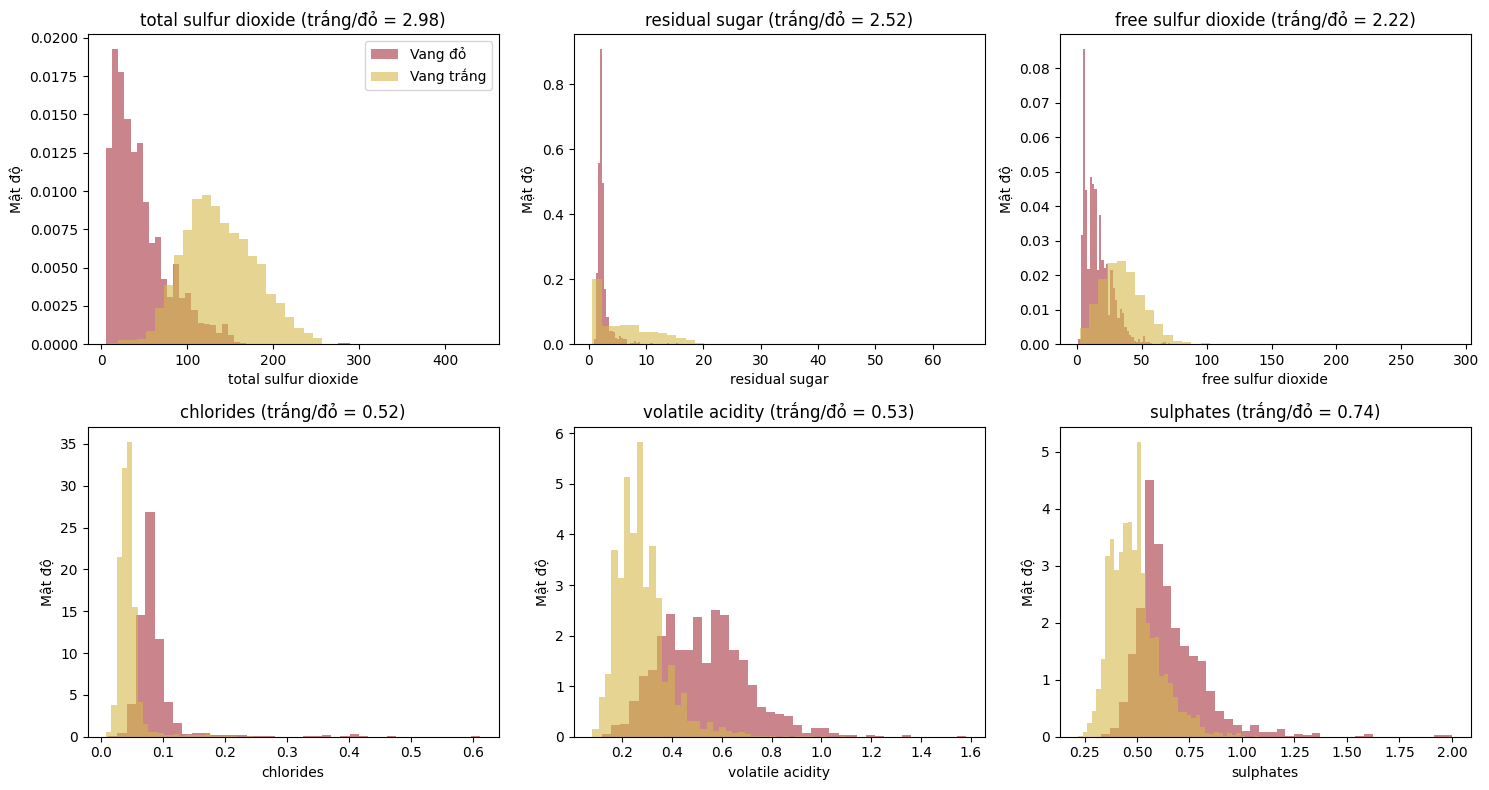

In [5]:
mean_type = wine.groupby("wine_type")[feat_cols].mean().T
mean_type.columns = ["Vang đỏ", "Vang trắng"]
mean_type["Trắng / Đỏ"] = mean_type["Vang trắng"] / mean_type["Vang đỏ"]
print("=== Trung bình từng đặc trưng theo loại rượu ===")
print(mean_type.round(3).to_string())
mean_type.round(4).to_csv("../output/trung_binh_theo_loai.csv")

# Hình: phân bố 6 đặc trưng khác nhau nhiều nhất giữa hai loại rượu
diff6 = (mean_type["Trắng / Đỏ"].apply(lambda r: max(r, 1 / r))).sort_values(ascending=False).index[:6]
type_names = {"red": "Vang đỏ", "white": "Vang trắng"}
type_colors = {"red": "#a8323e", "white": "#d4b84a"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), diff6):
    for t in ["red", "white"]:
        ax.hist(wine.loc[wine["wine_type"] == t, c], bins=40, alpha=0.6, density=True,
                color=type_colors[t], label=type_names[t])
    ax.set_title(f"{c} (trắng/đỏ = {mean_type.loc[c, 'Trắng / Đỏ']:.2f})")
    ax.set_xlabel(c)
    ax.set_ylabel("Mật độ")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("../output/dac_trung_theo_loai.png", dpi=150)
plt.show()

**Nhận xét:**
- **SO₂ là khác biệt lớn nhất:** tổng SO₂ của rượu trắng gấp khoảng 3 lần rượu đỏ (khoảng 138 so với 46 mg/dm³), SO₂ tự do gấp khoảng 2,2 lần. Rượu trắng không có tanin từ vỏ nho để chống oxy hóa nên phải dùng SO₂ nhiều hơn.
- **Đường dư:** rượu trắng trung bình khoảng 6,4 g/dm³, rượu đỏ khoảng 2,5 g/dm³; một số rượu trắng ngọt kéo dài đuôi tới 65,8 g/dm³.
- **Axit và muối:** rượu đỏ có độ axit bay hơi (khoảng 0,53 so với 0,28 g/dm³), muối clorua và sunfat cao hơn rõ; độ axit cố định cũng cao hơn.
- **Cồn và pH** gần như giống nhau giữa hai loại.
- Vì hóa học khác nhau rõ, **giữ biến `wine_type`** khi gộp để chia tập phân tầng theo loại rượu; các đặc trưng hóa lý (SO₂, axit bay hơi, clorua) đã gần như nhận diện được loại rượu, nên `wine_type` có thể không cần làm đầu vào mô hình (kiểm chứng ở bước chọn đặc trưng).